# Twelve-month IPCA forecast errors

For each completed year from 2001 to 2025, this notebook selects the last Focus annual IPCA forecast **on or before December 31 of the preceding year**. It compares that forecast with the realized IPCA for the target year. The signed error is `forecast − realized`, measured in percentage points; a positive value means the forecast was too high.

Focus source: the validated local SQLite snapshot in `dados/atual.json`, table `ExpectativasMercadoAnuais`, filtered to `Indicador = 'IPCA'`, `IndicadorDetalhe IS NULL`, and `baseCalculo = 0`. Realized values: the annual IPCA table in the [IBGE December 2025 report, page 23](https://ftp.ibge.gov.br/Precos_Indices_de_Precos_ao_Consumidor/INPC/Fasciculo_Indicadores_IBGE/ipca-inpc_202512caderno.pdf), transcribed to `projects/data/ibge_ipca_annual_2001_2025.csv`. No future year is included.

## 1. Load the snapshot and realized values

Run this notebook from the repository root or from `projects/`. The companion CSV is versioned; the Focus SQLite snapshot is local and must be recreated when working from a fresh clone.

In [1]:
suppressPackageStartupMessages({
  library(DBI)
  library(RSQLite)
  library(jsonlite)
})

project_root <- if (file.exists('dados/atual.json')) {
  '.'
} else if (file.exists('../dados/atual.json')) {
  '..'
} else {
  stop('Cannot find dados/atual.json; run from the repository root or projects/.')
}

snapshot <- fromJSON(file.path(project_root, 'dados/atual.json'))
realized <- read.csv(file.path(project_root, 'projects/data/ibge_ipca_annual_2001_2025.csv'))
stopifnot(identical(realized$year, 2001:2025), !anyNA(realized))
cat('Focus snapshot:', snapshot$coleta, '\n')
cat('Completed target years:', min(realized$year), 'to', max(realized$year), '\n')

Focus snapshot: 20261029T204913Z 


Completed target years: 2001 to 2025 


## 2. Select one 12-month forecast for each target year

The checkpoint is December 31 of year `Y − 1`. A forecast must be dated on or before that checkpoint and no more than seven calendar days earlier. The seven-day guard prevents an old forecast from being treated as a current one when observations are missing.

In [2]:
con <- dbConnect(SQLite(), file.path(project_root, snapshot$banco))
focus <- tryCatch(
  do.call(rbind, lapply(realized$year, function(year) {
    anchor <- sprintf('%04d-12-31', year - 1L)
    row <- dbGetQuery(con, '
      SELECT Data AS forecast_date, Mediana AS forecast_ipca_pct,
             DesvioPadrao AS forecast_sd_pp, numeroRespondentes AS respondents
      FROM ExpectativasMercadoAnuais
      WHERE Indicador = ? AND IndicadorDetalhe IS NULL
        AND DataReferencia = ? AND baseCalculo = ? AND Data <= ?
      ORDER BY Data DESC LIMIT 1
    ', params = list('IPCA', as.character(year), 0L, anchor))
    if (nrow(row) != 1L || anyNA(row[c('forecast_ipca_pct', 'forecast_sd_pp')])) {
      stop('Missing or incomplete Focus forecast for target year ', year)
    }
    gap <- as.integer(as.Date(anchor) - as.Date(row$forecast_date))
    if (gap < 0L || gap > 7L) stop('Forecast too far from checkpoint for ', year)
    data.frame(year = year, anchor_date = anchor,
               forecast_date = row$forecast_date,
               days_before_anchor = gap,
               forecast_ipca_pct = row$forecast_ipca_pct,
               forecast_sd_pp = row$forecast_sd_pp,
               respondents = row$respondents)
  })),
  finally = dbDisconnect(con)
)
stopifnot(nrow(focus) == nrow(realized), !anyDuplicated(focus$year))
head(focus, 5)

,year,anchor_date,forecast_date,days_before_anchor,forecast_ipca_pct,forecast_sd_pp,respondents
,<int>,<chr>,<chr>,<int>,<dbl>,<dbl>,<int>
1,2001,2000-12-31,2000-12-29,2,4.3,0.38,NA
2,2002,2001-12-31,2001-12-31,0,4.8,0.59,NA
3,2003,2002-12-31,2002-12-31,0,11.0,2.27,NA
4,2004,2003-12-31,2003-12-30,1,6.0,0.49,NA
5,2005,2004-12-31,2004-12-30,1,5.7,0.46,NA


## 3. Calculate forecast errors

Both the forecast and realized IPCA are percentages. Their difference is therefore in percentage points. `forecast_sd_pp` describes disagreement among submitted forecasts and is retained for the later analysis; it is not part of the error formula.

In [3]:
focus$realized_ipca_pct <- realized$realized_ipca_pct[match(focus$year, realized$year)]
stopifnot(!anyNA(focus$realized_ipca_pct))
focus$error_pp <- focus$forecast_ipca_pct - focus$realized_ipca_pct
focus$absolute_error_pp <- abs(focus$error_pp)

print(focus[c('year', 'forecast_date', 'forecast_ipca_pct',
              'realized_ipca_pct', 'error_pp', 'absolute_error_pp',
              'forecast_sd_pp')], row.names = FALSE, digits = 4)

 year forecast_date forecast_ipca_pct realized_ipca_pct error_pp
 2001    2000-12-29             4.300              7.67  -3.3700
 2002    2001-12-31             4.800             12.53  -7.7300
 2003    2002-12-31            11.000              9.30   1.7000
 2004    2003-12-30             6.000              7.60  -1.6000
 2005    2004-12-30             5.700              5.69   0.0100
 2006    2005-12-30             4.500              3.14   1.3600
 2007    2006-12-29             4.000              4.46  -0.4600
 2008    2007-12-31             4.300              5.90  -1.6000
 2009    2008-12-31             5.000              4.31   0.6900
 2010    2009-12-31             4.500              5.91  -1.4100
 2011    2010-12-31             5.320              6.50  -1.1800
 2012    2011-12-30             5.320              5.84  -0.5200
 2013    2012-12-31             5.470              5.91  -0.4400
 2014    2013-12-31             5.970              6.41  -0.4400
 2015    2014-12-31      

## 4. Summarize and inspect the errors

 years mean_signed_error_pp mean_absolute_error_pp median_absolute_error_pp
    25              -0.9842                  1.616                     0.91
 rmse_pp
   2.494


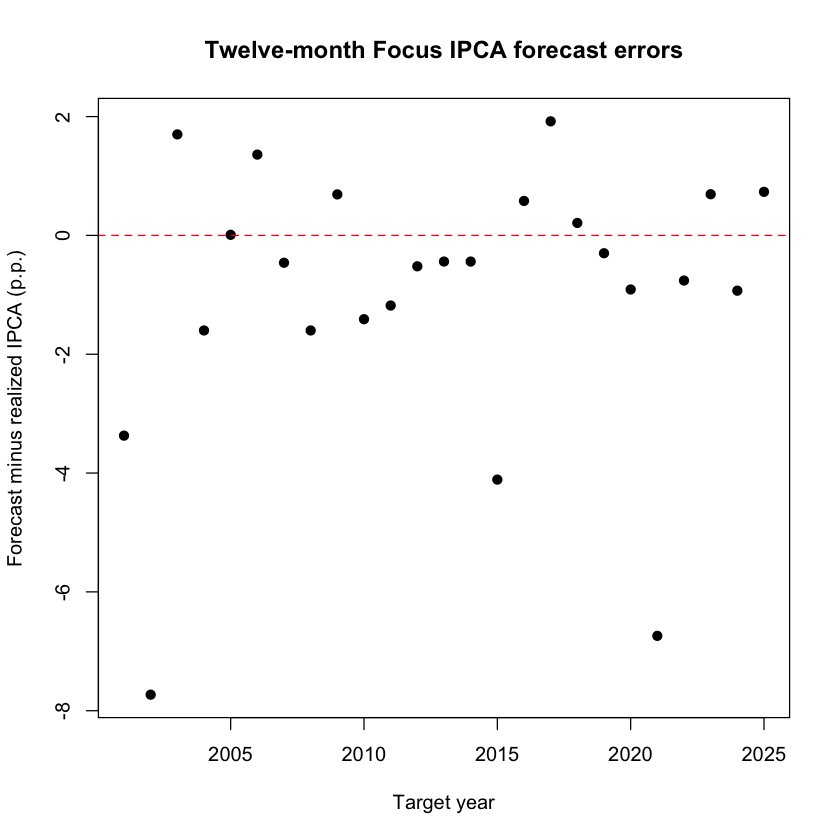

In [4]:
summary_12m <- data.frame(
  years = nrow(focus),
  mean_signed_error_pp = mean(focus$error_pp),
  mean_absolute_error_pp = mean(focus$absolute_error_pp),
  median_absolute_error_pp = median(focus$absolute_error_pp),
  rmse_pp = sqrt(mean(focus$error_pp^2))
)
print(summary_12m, row.names = FALSE, digits = 4)

plot(focus$year, focus$error_pp, pch = 19,
     xlab = 'Target year', ylab = 'Forecast minus realized IPCA (p.p.)',
     main = 'Twelve-month Focus IPCA forecast errors')
abline(h = 0, col = 'red', lty = 2)

These are **25 historical annual errors**, not 25 independent daily forecasts. The next project step can add six- and three-month checkpoints and compare them using the same target years.

## 5. Distribution of signed forecast errors

Negative errors mean the Focus median underestimated realized inflation; positive errors mean it overestimated inflation.

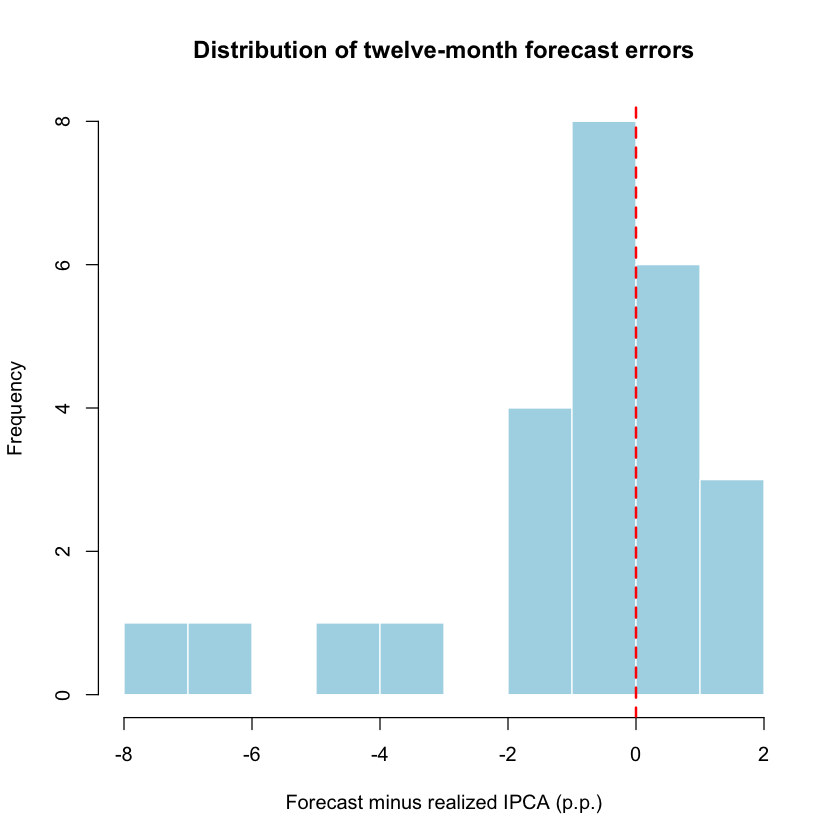

In [5]:
par(bg = 'white')
hist(focus$error_pp, breaks = 'FD', col = 'lightblue', border = 'white',
     main = 'Distribution of twelve-month forecast errors',
     xlab = 'Forecast minus realized IPCA (p.p.)')
abline(v = 0, col = 'red', lty = 2, lwd = 2)